<center><h1>Dong_Fengkai_HW6</h1></center>
<br>
<br>

Name: Fengkai Dong
<br>
Github Username: dfk0411
<br>
USC ID: 

## 1. Tree-Based Methods

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

### (a) Download the APS Failure data

In [2]:
train = pd.read_csv("../data/aps_failure_training_set.csv", skiprows=20, na_values="na")
test = pd.read_csv("../data/aps_failure_test_set.csv", skiprows=20, na_values="na")
print("Training set shape:", train.shape)
print("Test set shape:", test.shape)

Training set shape: (60000, 171)
Test set shape: (16000, 171)


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Common missing value imputation methods include mean, median, mode, KNN, and iterative imputation.

Choose median imputation because it is less sensitive to outliers and computationally efficient.

#### (ii) Calculate the coefficient of variation

In [3]:
x_train = train.drop(columns="class")
x_test = test.drop(columns="class")
train_medians = x_train.median()
x_train = x_train.fillna(train_medians)
x_test = x_test.fillna(train_medians)
cv = x_train.std() / x_train.mean()
display(cv)

aa_000      2.450938
ab_000     10.383494
ac_000      2.310241
ad_000    244.322816
ae_000     24.200137
             ...    
ee_007      5.012754
ee_008      3.259079
ee_009      5.691612
ef_000     49.366659
eg_000     42.481747
Length: 170, dtype: float64

#### (iii) Plot a correlation matrix

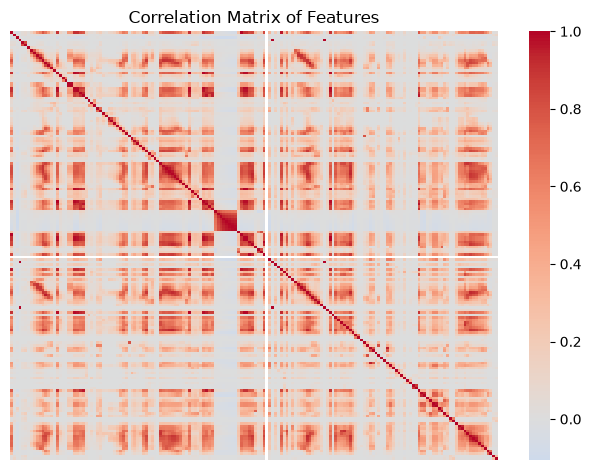

In [4]:
corr = x_train.corr()
sns.heatmap(
    corr, 
    cmap="coolwarm", 
    center=0,
    xticklabels=False, 
    yticklabels=False
)
plt.title("Correlation Matrix of Features")
plt.tight_layout()
plt.show()

#### (iv) Make scatter plots and box plots

Selected features: ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


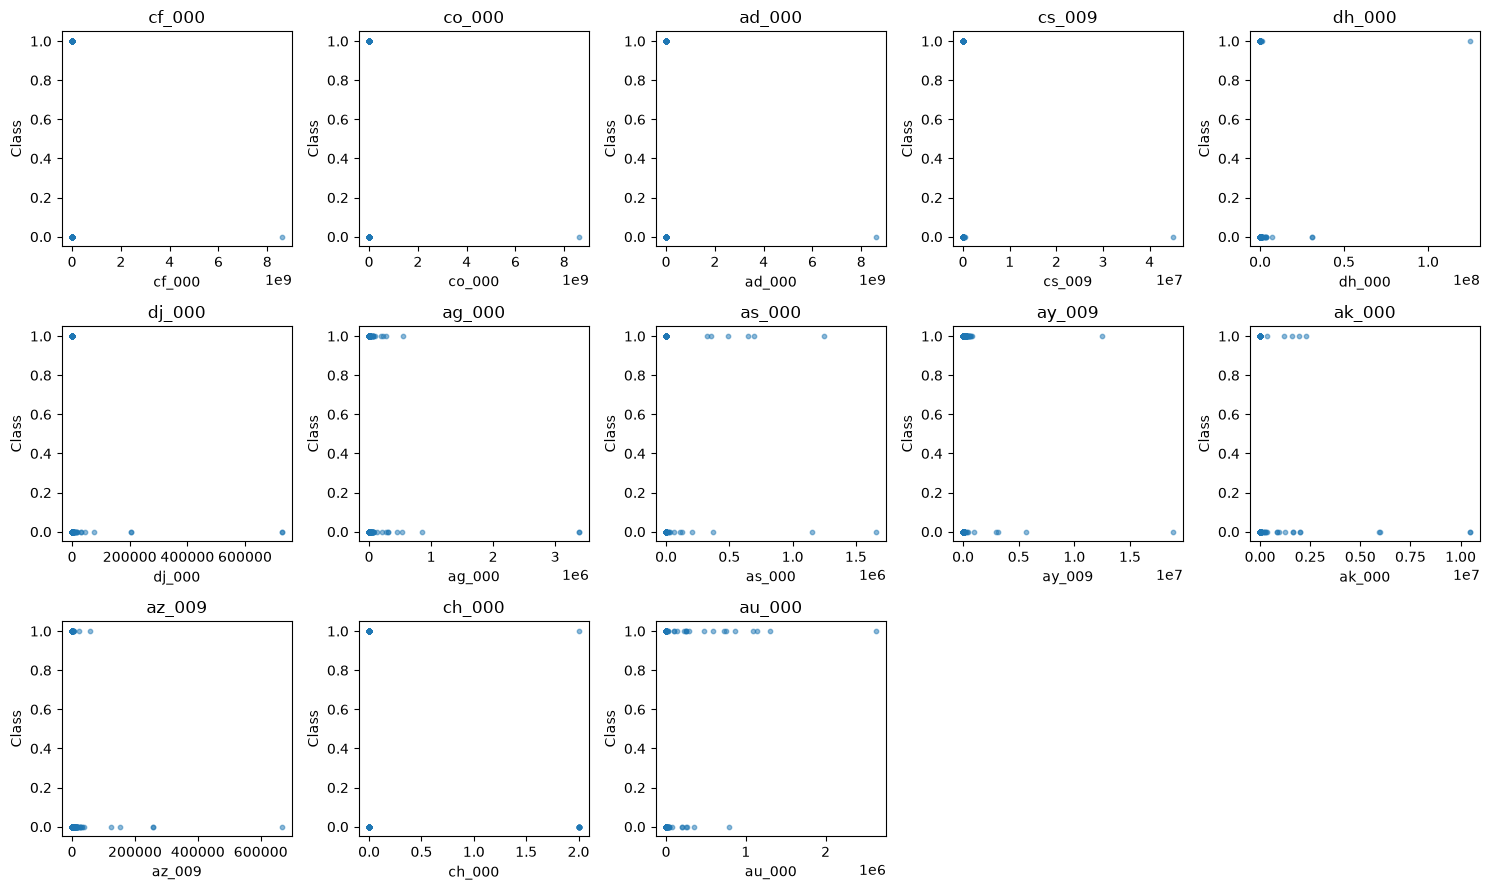

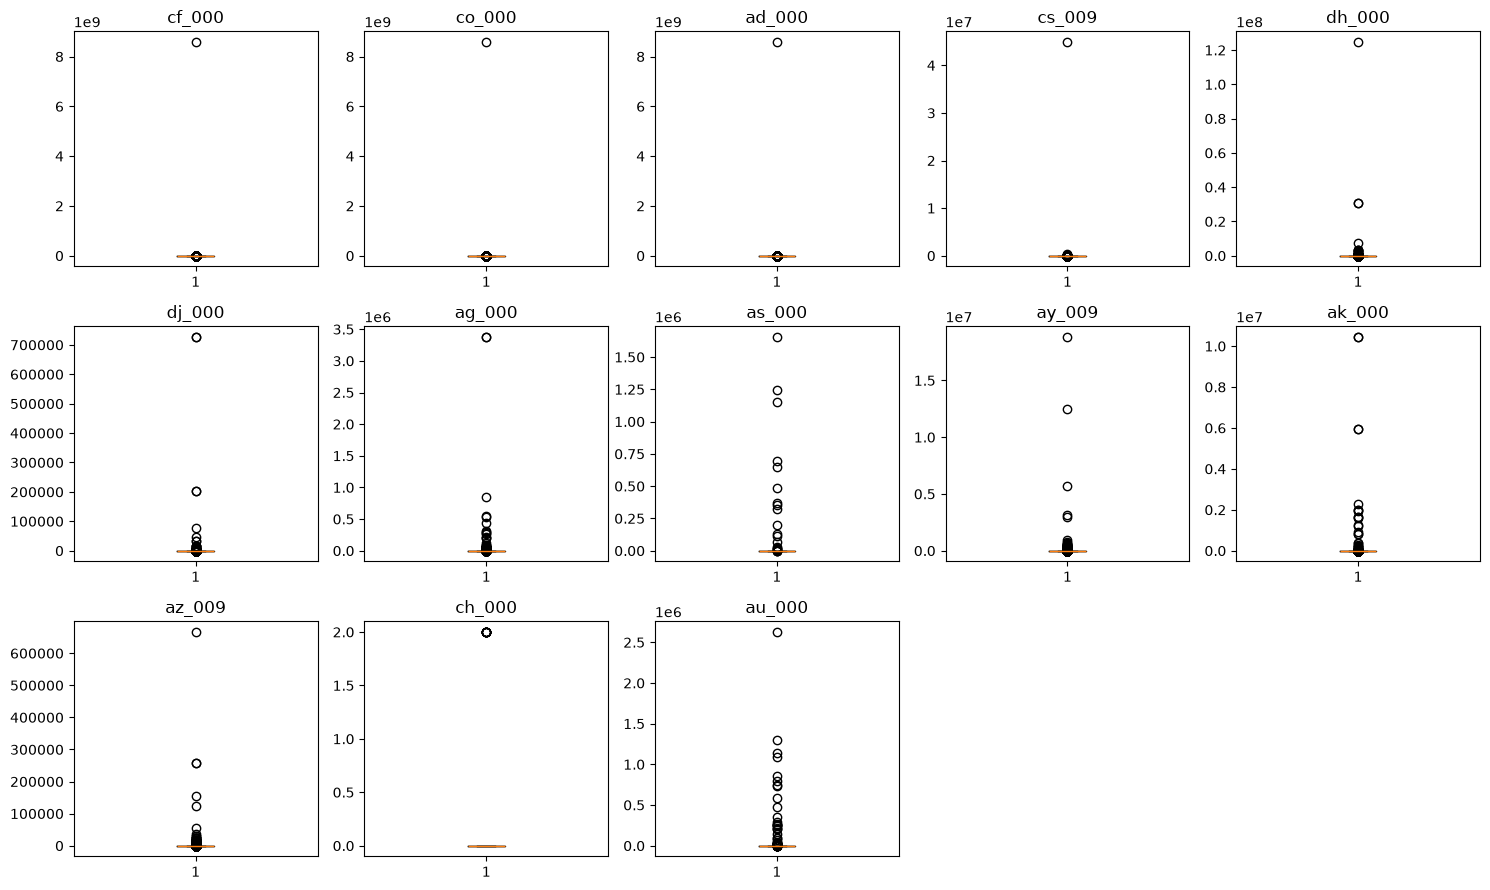

In [5]:
top = cv.nlargest(13).index
print("Selected features:", top.tolist())
y_train = train["class"].map({"neg": 0, "pos": 1})

fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for ax, feature in zip(axes.flat, top):
    ax.scatter(x_train[feature], y_train, s=10, alpha=0.5)
    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("Class")
for ax in axes.flat[13:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for ax, feature in zip(axes.flat, top):
    ax.boxplot(x_train[feature])
    ax.set_title(feature)
for ax in axes.flat[13:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

Most selected features have lots of values close to 0 and some values extremely large. The scatter plots don't show clear linear relationships for almost all selected features, and we can't determine the significance of these features from scatter plots.

#### (v) Is this data set imbalanced?

In [6]:
print("Training set:")
print(train["class"].value_counts())
print("\nTest set:")
print(test["class"].value_counts())

Training set:
class
neg    59000
pos     1000
Name: count, dtype: int64

Test set:
class
neg    15625
pos      375
Name: count, dtype: int64


The dataset is highly imbalanced. In the training set, there are 59,000 negative samples and only 1,000 positive samples. In the test set, there are 15,625 negative samples and 375 positive samples. The proportion of positive samples is very low.

### (c) Train a random forest

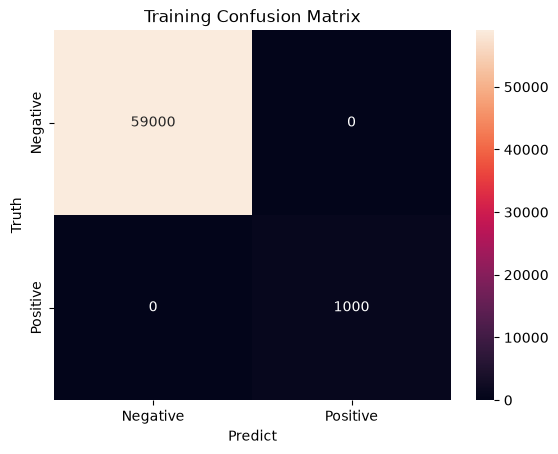

Training AUC: 1.000000
Training Error: 0.000000



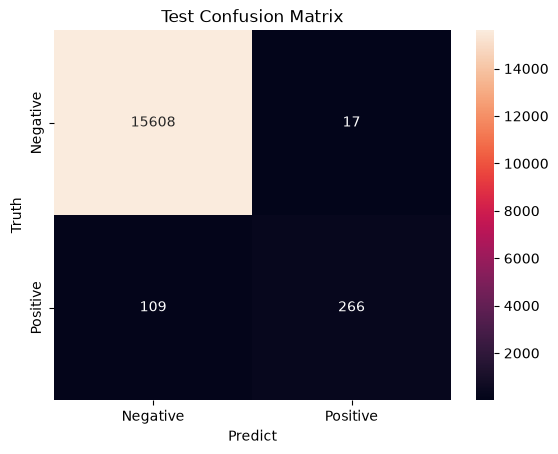

Test AUC: 0.995537
Test Error: 0.007875



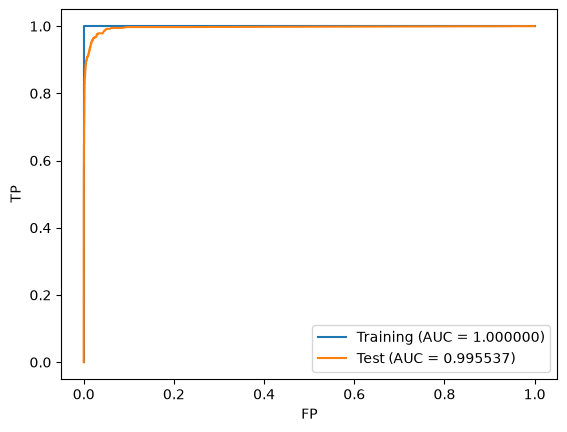

OOB Error: 0.005733333333333368
Test Error: 0.007874999999999965


In [7]:
y_test = test["class"].map({"neg": 0, "pos": 1})
rf = RandomForestClassifier(
    n_estimators=1000,
    oob_score=True,
    random_state=1,
    n_jobs=-1
)
rf.fit(x_train, y_train)
roc_results = []
for name, x, y in [("Training", x_train, y_train), ("Test", x_test, y_test)]:
    y_pred = rf.predict(x)
    y_prob = rf.predict_proba(x)[:, 1]
    cm = confusion_matrix(y, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
    plt.title(f"{name} Confusion Matrix")
    plt.xlabel("Predict")
    plt.ylabel("Truth")
    plt.show()
    error = 1 - accuracy_score(y, y_pred)
    fpr, tpr, _ = roc_curve(y, y_prob)
    auc = roc_auc_score(y, y_prob)
    print(f"{name} AUC: {auc:.6f}")
    print(f"{name} Error: {error:.6f}\n")
    roc_results.append((name, fpr, tpr, auc))
    
for name, fpr, tpr, auc in roc_results:
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.6f})")
plt.xlabel("FP")
plt.ylabel("TP")
plt.legend()
plt.show()
oob_error = 1 - rf.oob_score_
print("OOB Error:", oob_error)
print("Test Error:", 1 - accuracy_score(y_test, y_pred))

The random forest has a training AUC of 1 and a test AUC of 0.995537, with misclassification errors of 0 and 0.007875, respectively. The OOB error is 0.005733, which is close to the test error.

### (d) Research class imbalance in random forest

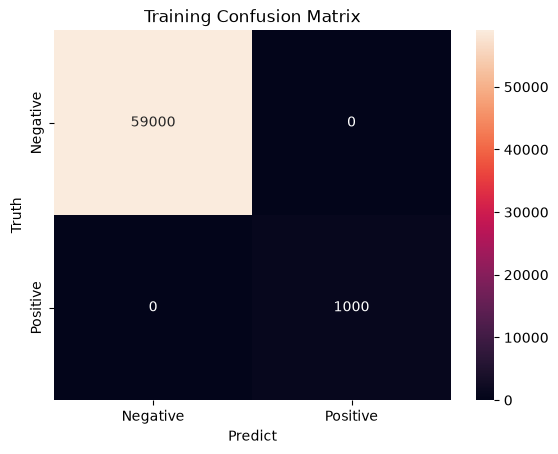

Training AUC: 1.000000
Training Error: 0.000000



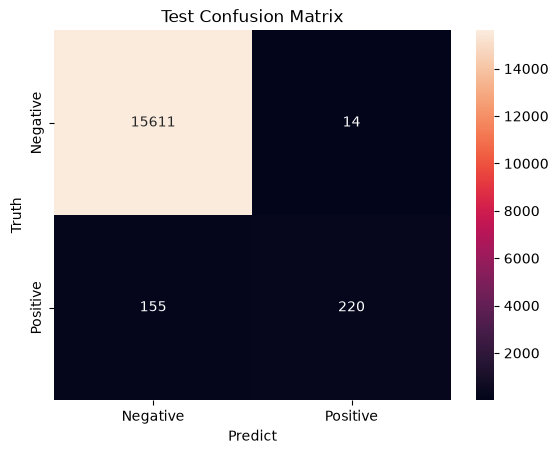

Test AUC: 0.994348
Test Error: 0.010563



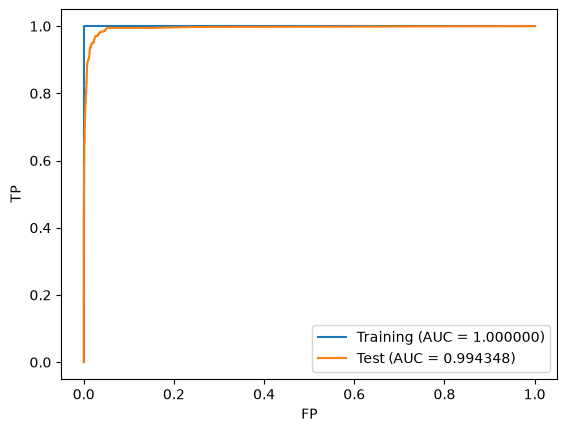

OOB Error: 0.007483333333333286
Test Error: 0.01056250000000003


In [8]:
rf_balance = RandomForestClassifier(
    n_estimators=1000,
    class_weight="balanced_subsample",
    oob_score=True,
    random_state=1,
    n_jobs=-1
)
rf_balance.fit(x_train, y_train)
roc_results = []
for name, x, y in [("Training", x_train, y_train), ("Test", x_test, y_test)]:
    y_pred = rf_balance.predict(x)
    y_prob = rf_balance.predict_proba(x)[:, 1]
    cm = confusion_matrix(y, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
    plt.title(f"{name} Confusion Matrix")
    plt.xlabel("Predict")
    plt.ylabel("Truth")
    plt.show()
    error = 1 - accuracy_score(y, y_pred)
    fpr, tpr, _ = roc_curve(y, y_prob)
    auc = roc_auc_score(y, y_prob)
    print(f"{name} AUC: {auc:.6f}")
    print(f"{name} Error: {error:.6f}\n")
    roc_results.append((name, fpr, tpr, auc))

for name, fpr, tpr, auc in roc_results:
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.6f})")
plt.xlabel("FP")
plt.ylabel("TP")
plt.legend()
plt.show()
balanced_oob_error = 1 - rf_balance.oob_score_
print("OOB Error:", balanced_oob_error)
print("Test Error:", 1 - accuracy_score(y_test, y_pred))

Compared with the original random forest, the balanced model has the test AUC reduced to 0.994348, and has the test misclassification error increased to 0.010563. The training AUC and training error remain the same. The OOB error is 0.007483, which is slightly lower than the test error.

### (e) XGBoost and Model Trees

Best alpha: 0.521400828799969
CV Error: 0.0057833333333332515


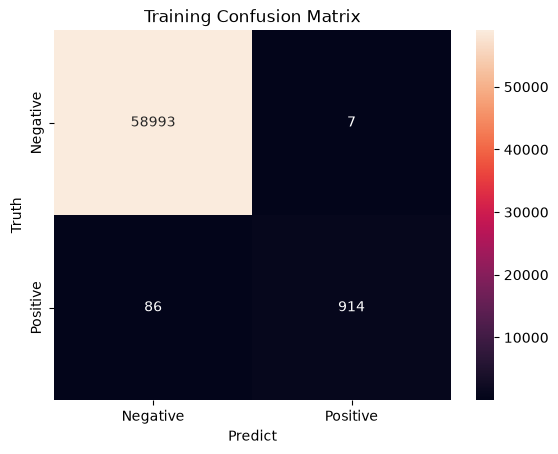

Training AUC: 0.999384
Training Error: 0.001550


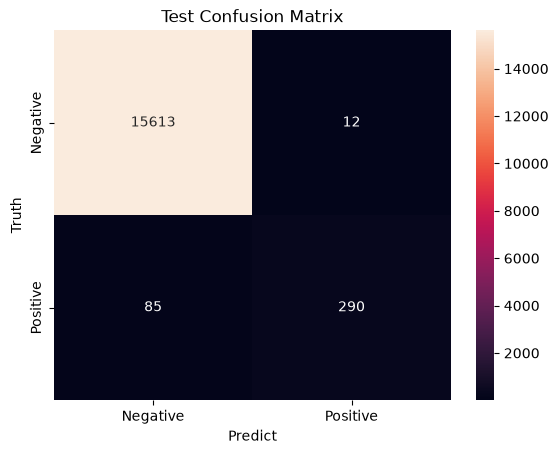

Test AUC: 0.996138
Test Error: 0.006062


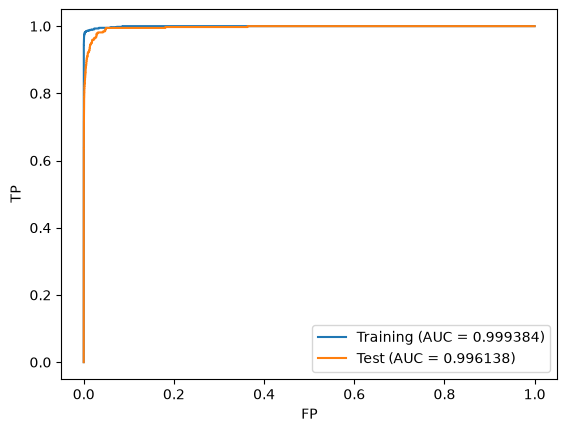

In [9]:
x_train = train.drop(columns="class")
x_test = test.drop(columns="class")

xgb = XGBClassifier(
    n_estimators=1000,
    max_depth=5,
    learning_rate=0.01,
    objective="binary:logistic",
    random_state=1,
    n_jobs=1
)
xgb_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("xgb", xgb)
])
cv_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
grid = GridSearchCV(
    xgb_pipe,
    {"xgb__reg_alpha": np.logspace(-4, 4, 100)},
    cv=cv_folds,
    scoring="accuracy",
    n_jobs=-1
)
grid.fit(x_train, y_train)
print("Best alpha:", grid.best_params_["xgb__reg_alpha"])
print("CV Error:", 1-grid.best_score_)
roc_results = []
for name, x, y in [("Training", x_train, y_train), ("Test", x_test, y_test)]:
    y_pred = grid.predict(x)
    y_prob = grid.predict_proba(x)[:, 1]
    cm = confusion_matrix(y, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
    plt.title(f"{name} Confusion Matrix")
    plt.xlabel("Predict")
    plt.ylabel("Truth")
    plt.show()
    error = 1 - accuracy_score(y, y_pred)
    fpr, tpr, _ = roc_curve(y, y_prob)
    auc = roc_auc_score(y, y_prob)
    print(f"{name} AUC: {auc:.6f}")
    print(f"{name} Error: {error:.6f}")
    roc_results.append((name, fpr, tpr, auc))

for name, fpr, tpr, auc in roc_results:
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.6f})")
plt.xlabel("FP")
plt.ylabel("TP")
plt.legend()
plt.show()

### (f) Use SMOTE to pre-process your data

Best alpha: 0.022051307399030457
CV Error: 0.012749999999999928


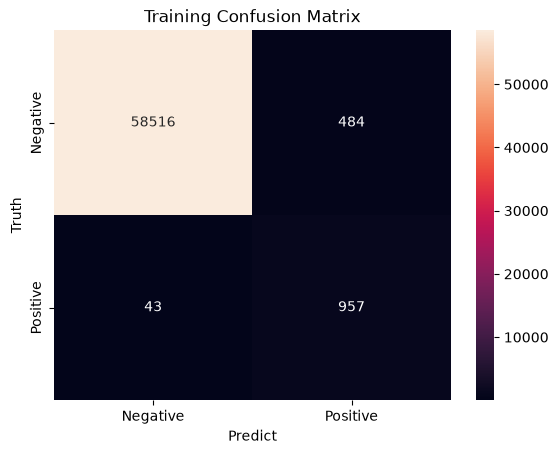

Training AUC: 0.998475
Training Error: 0.008783


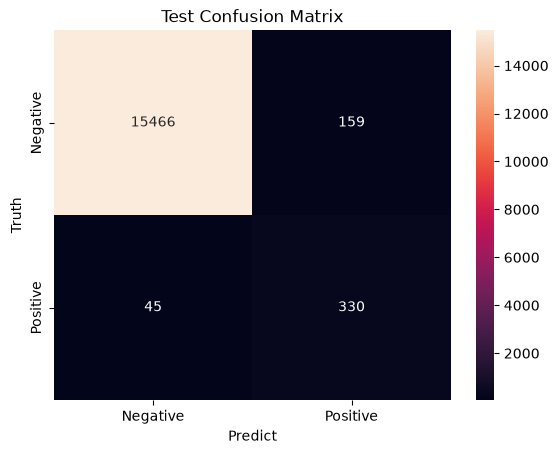

Test AUC: 0.993928
Test Error: 0.012750


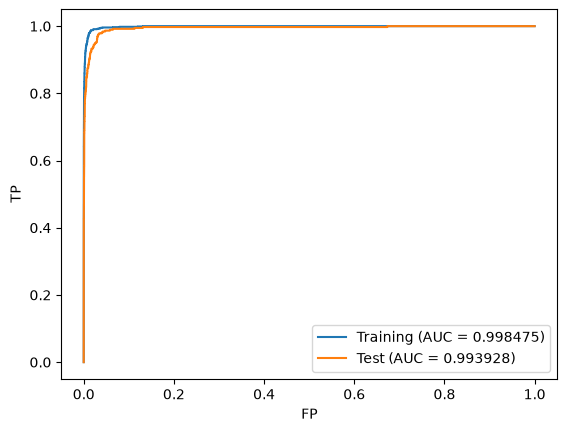

In [10]:
smote_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=1)),
    ("xgb", xgb)
])
grid = GridSearchCV(
    smote_pipe,
    {"xgb__reg_alpha": np.logspace(-4, 4, 100)},
    cv=cv_folds,
    scoring="accuracy",
    n_jobs=-1
)
grid.fit(x_train, y_train)
print("Best alpha:", grid.best_params_["xgb__reg_alpha"])
print("CV Error:", 1-grid.best_score_)
roc_results = []
for name, x, y in [("Training", x_train, y_train),
                   ("Test", x_test, y_test)]:
    y_pred = grid.predict(x)
    y_prob = grid.predict_proba(x)[:, 1]
    cm = confusion_matrix(y, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
    plt.title(f"{name} Confusion Matrix")
    plt.xlabel("Predict")
    plt.ylabel("Truth")
    plt.show()
    error = 1 - accuracy_score(y, y_pred)
    fpr, tpr, _ = roc_curve(y, y_prob)
    auc = roc_auc_score(y, y_prob)
    print(f"{name} AUC: {auc:.6f}")
    print(f"{name} Error: {error:.6f}")
    roc_results.append((name, fpr, tpr, auc))

for name, fpr, tpr, auc in roc_results:
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.6f})")
plt.xlabel("FP")
plt.ylabel("TP")
plt.legend()
plt.show()

Compared with XGBoost without SMOTE, the SMOTE model reduced false negatives from 85 to 45, improving positive-class recall from 77.33% to 88%. However, false positives increased from 12 to 159, and test misclassification error increased from 0.006062 to 0.012750. The test AUC also decreased slightly from 0.996138 to 0.993928. The CV error is 0.012750, which is close to the test error.

## 2. ISLR 6.6.3

(a) iv. Steadily decrease. Increasing $s$ allows the model to use a wider range of coefficient combinations, so the minimum training RSS cannot increase.

(b) ii. Decrease initially, then start increasing in a U shape. Increasing model flexibility initially reduces underfitting, but excessive flexibility can cause overfitting, leading to higher test RSS.

(c) iii. Steadily increase. As the constraint becomes less restrictive, the model becomes more flexible and more sensitive to variations in the training data, causing the variance to increase.

(d) iv. Steadily decrease. As the model become more flexible, the model can better approximate the relationship, reducing the squared bias.

(e) v. Remain constant. Irreducible error depends on the noise or randomness of the data, and cannot be affected by the choice of $s$.

## 3. ISLR 6.6.5


### (a)

Since $x_{11}=x_{12}$, $x_{21}=x_{22}$, $x_{11}+x_{21}=0$, and $y_1+y_2=0$, let $x=x_{11}=x_{12}$ and $y=y_1$, the ridge optimization problem becomes

$$
min_{\beta}(\sum_{i=1}^{2}(y_i-\hat{\beta_0}-\sum_{j=1}^{2}\beta_j x_{ij})^2 + \lambda\sum_{j=1}^{2}\beta_j^2)
=\min_{\beta_1,\beta_2}(2[y-x(\beta_1+\beta_2)]^2+\lambda(\beta_1^2+\beta_2^2)).
$$

### (b)

Taking the partial derivatives and let them be zero,

$$
\frac{\partial L}{\partial\beta_1}
=-4x[y-x(\beta_1+\beta_2)]+2\lambda\beta_1=0,
\frac{\partial L}{\partial\beta_2}
=-4x[y-x(\beta_1+\beta_2)]+2\lambda\beta_2=0.
$$

Therefore, 

$$
\frac{\partial L}{\partial\beta_1}-\frac{\partial L}{\partial\beta_2}
=2\lambda(\beta_1-\beta_2)=0.
$$

So for $\lambda>0$, $\hat{\beta}_1=\hat{\beta}_2.$

### (c)

The lasso optimization problem is

$$
min_{\beta}(\sum_{i=1}^{2}(y_i-\hat{\beta_0}-\sum_{j=1}^{2}\beta_j x_{ij})^2 + \lambda\sum_{j=1}^{2}|\beta_j|)
=\min_{\beta_1,\beta_2}(2[y-x(\beta_1+\beta_2)]^2+\lambda(|\beta_1|+|\beta_2|)).
$$

### (d)

Let $t=\beta_1+\beta_2$. The problem becomes

$$
\min_{\beta_1,\beta_2}2[y-x(\beta_1+\beta_2)]^2+\lambda(|\beta_1|+|\beta_2|)
\geq min_{\beta_1,\beta_2}(2[y-x(\beta_1+\beta_2)]^2+\lambda(|\beta_1+\beta_2|))
=min_t(2(y-xt)^2+\lambda t).
$$

The equality holds when $\beta_1$ and $\beta_2$ have the same sign or one is zero. So any pair satisfying 
$\beta_1=a, \beta_2=t-a, 0\leq a\leq t \text{ or } 0\leq a\leq t$ is a solution.

Thus, when $t\neq 0$, the lasso coefficients are not unique. If $t=0$ and $\lambda>0$, there is a unique solution $(0,0)$.


## 4. ISLR 8.4.5


### Majority Vote:

There are six probabilities greater than 0.5 meaning six trees predict red. Other four trees predict green.
So the final classification is red.

### Average Probability:

The average predicted probability of red is

$$
\bar{P}(\text{Red}\mid X)
=\frac{0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75}{10}
=\frac{4.5}{10}=0.45.
$$

Since $0.45<0.5$, the final classification is green.


## 5. ISLR 9.7.3

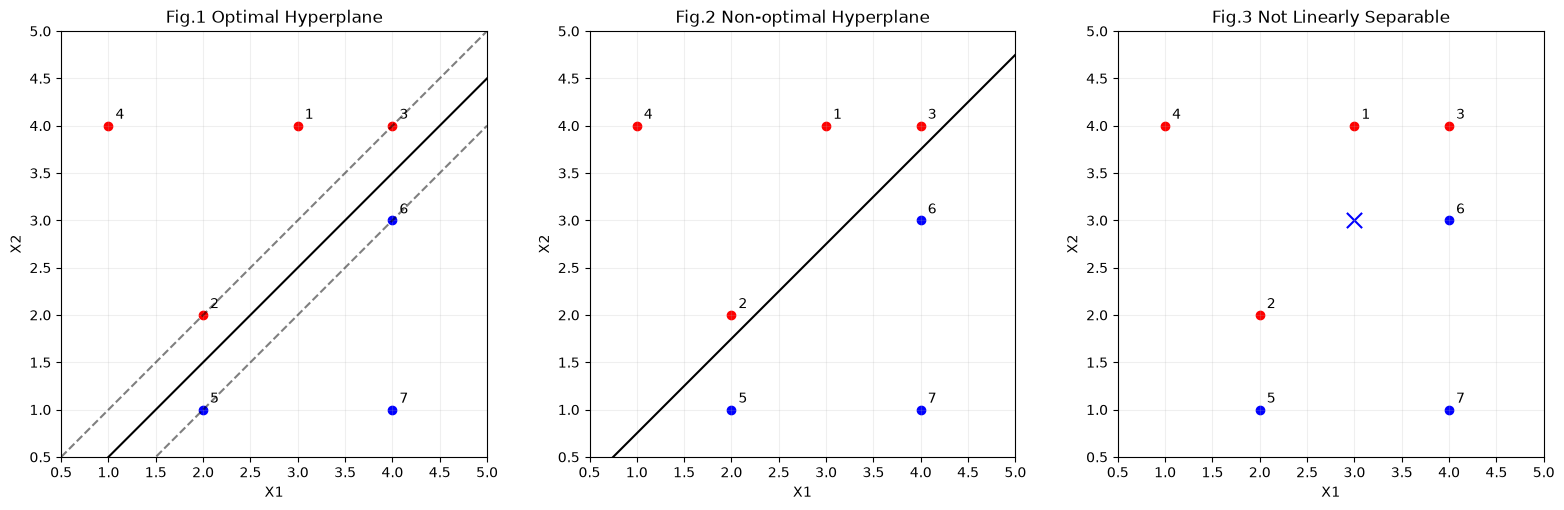


### (a)

The observations are plotted in Fig.1.

### (b)

The optimal separating hyperplane is plotted in Fig.1. The equation is $0.5-X_1+X_2=0.$

### (c)

The classification rule is "Classify to Red if $0.5-X_1+X_2>0$, and classify to Blue otherwise."
$\beta_0=0.5$, $\beta_1=-1$, $\beta_2=1$.

### (d)

The two margin boundaries are plotted in Fig.1. Their equations are $-X_1+X_2=0$, $1-X_1+X_2=0.$

### (e)

The support vectors are observations 2, 3, 5, and 6.

### (f)

Observation 7 is not a support vector because it's not on the margin. A slight movement of observation 7 will not change the optimal hyperplane, provided that its position remains on the correct side of the margin.

### (g)

One non-optimal separating hyperplane is plotted in Fig.2. The equation is $0.25-X_1+X_2=0.$

### (h)

Add a Blue observation at (3,3), as shown in Fig.3. This point lies on the line segment connecting two Red observations $(2,2)$ and $(4,4)$. 
In this case, no linear hyperplane can classify both observations as Red while classifying the added observation between them as Blue.
